# Chapter 8: Convolutional Neural Networks

### Cifar2 Data from Ch 7.

In [110]:
import torch
from torchvision import datasets, transforms

# Getting cifar10 dataset
data_path = 'data/ch7'  # Path to cifar10 data from ch 7.  
cifar10 = datasets.CIFAR10(data_path, train=True, download=True, transform=transforms.ToTensor()) 
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transforms.ToTensor())
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Normalizing Data
imgs = torch.stack([img_t for img_t, _ in cifar10], dim = 3)

data_mean = imgs.view(3, -1).mean(dim=1).tolist()
data_std = imgs.view(3, -1).std(dim=1).tolist()

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize(mean=data_mean, std=data_std)])

cifar10 = datasets.CIFAR10(data_path, train=True, download=True, transform=transform) 
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transform)

# Building cifar2 dataset
label_map = {0:0, 2:1}  # Remaps label 2 (birds) in CIFAR dataset to be label 1 for our dataset
class_names = ['airplane', 'bird']
cifar2 = [(img, label_map[label]) for img, label in cifar10 if label in [0, 2]]
cifar2_val = [(img, label_map[label]) for img, label in cifar10_val if label in [0, 2]]

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


## Creating a Convolutional Module

- Torch.nn provides the nn.Conv modules for convolutions in 1, 2 and 3D \
  --> 1D is used for time series, 2D for images and 3D for volumetric data and videos
- Argumnments for layer: nn.Conv(input features/channels, output features, kernal_size) \
  --> More channels in output image (output features) = higher the network capcity -- Each channels detects 1 distinct feature. \
  --> If only 1 value is passed to kernal size, assumes square/cube. If want multiple values can pass as tuple ex. (3, 3) -- Common for kernal size to be same in all dim.
- A convolutional layer contains multiple kernels in weight matrix.
  --> Conv. weight shape = kernal_size x in_featu. (as seperate kernal is needed to handel each channel) x out_featu. (as each kernals detects diffrent patterns)

In [111]:
import torch
import torch.nn as nn

# Creating Conv2d for image
conv = nn.Conv2d(3, 16, kernel_size=3) # Arbitraily using 16 out. features -- to detect 16 distinct patterns/features
conv

# Check Conv. layer weight and bias
conv, conv.weight.shape, conv.bias.shape # Bias shape = # output featu. Since 1 val is added per out featu.

(Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1)),
 torch.Size([16, 3, 3, 3]),
 torch.Size([16]))

Passing an image through conv. to get output image
- 2D conv. produces 2D img where pixels are a weighted sum of a group of pixels (neighbourhood) in the input img
- layer expects a B x C x H x W tensor for image input. (Like all nn modules)

In [112]:
import matplotlib.pyplot as plt

# Getting sample img from cifar2
img, _ = cifar2[0]
img = img.unsqueeze(0) # Adding batch dim at idx 0

output = conv(img) # Pass through conv -- Won't produce anything useful --> weights and bias are randomly initialised
img.shape, output.shape

(torch.Size([1, 3, 32, 32]), torch.Size([1, 16, 30, 30]))

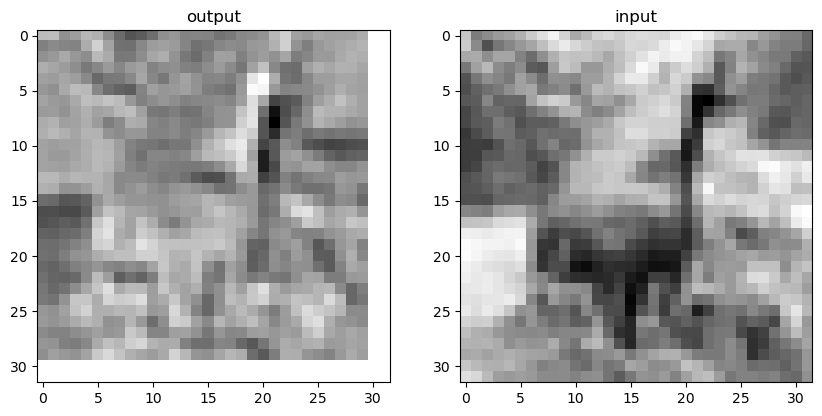

In [113]:
# Displaying output img
# %matplotlib inline
# plt.imshow(output[0, 0].detach(), cmap='gray')
# plt.show()

# Show both input and output
%matplotlib inline
plt.figure(figsize=(10, 4.8))
ax1 = plt.subplot(1, 2, 1)
plt.title('output')
plt.imshow(output[0, 0].detach(), cmap='gray')
plt.subplot(1, 2, 2, sharex=ax1, sharey=ax1) 
plt.imshow(img[0, 0], cmap='gray') 
plt.title('input') 
plt.show()

#### Adding Padding to img

- Since a convolution requires neighbours (of the kernal "radius") in all directions, from the center, to compute (the weighted sum and as a result) the output, at the edge of the images there will be no output. \
--> loosing (k-1 / 2) (for a k x k kenal) pixels on each side of the image
- Fix this by adding a padding (of ghost pixels) (of size k - 1 / 2) to the input image, by passing the padding size the the conv layer constuctor \
--> Padding would be diffrent of diff sizes for even kernal, so ***Stick to odd sized kernals***

In [114]:
conv = nn.Conv2d(3, 1, kernel_size=3, padding=1)
output = conv(img)
img.shape, output.shape

(torch.Size([1, 3, 32, 32]), torch.Size([1, 1, 32, 32]))

### Detecting Features with Convolutions

#### Hand setting conv weight to see effect


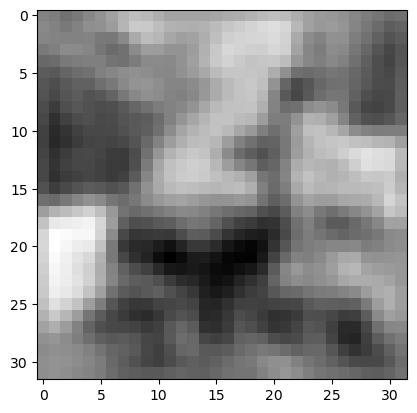

In [115]:
with torch.no_grad():
    conv.bias.zero_() # Zeroing bias

with torch.no_grad():
    conv.weight.fill_(1.0 / 9.0) # Making Each pixel in output get mean value of its 3 x 3 neighbours

# Applying convolution and viewing output image -- Produces blured image!
out = conv(img)
%matplotlib inline
plt.imshow(out[0, 0].detach(), cmap='gray')
plt.show()

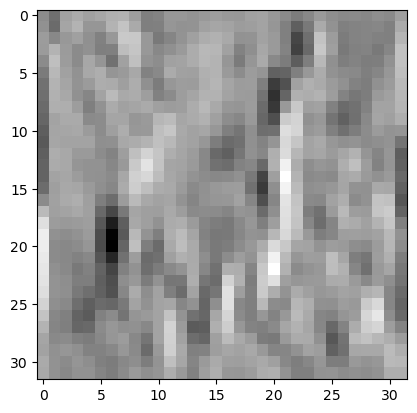

In [116]:
with torch.no_grad():
    conv.weight[:] = torch.tensor([[-1.0, 0.0, 1.0],
                                   [-1.0, 0.0, 1.0],
                                   [-1.0, 0.0, 1.0],
                                   ])
    conv.bias.zero_()

# Applying convolution and viewing output image -- Detects edges! --> Diffrence of pixels
out = conv(img)
%matplotlib inline
plt.imshow(out[0, 0].detach(), cmap='gray')
plt.show()

#### Downsampling Images

- The small kernal size won't capure the whole object we want, so we need a way to combine convolutions (distinct objects features) into the bigger picture (the whole object)
- The way to do this is to downsample (scale down the output) and stack sucessive convolutions
- The most common approach for downsampling is max poooling
  --> Take the maximum of a group of pixels and use that as the output. \
  (eg. To scale an img by half using max pooling, take the max value from a group 4 pixels and use that pixel as the 1 out.)
- Max Polling function (for 1, 2 and 3D data) is provided in torch.nn module

In [117]:
pool = nn.MaxPool2d(2) #MaxPool(input to pool (per dim))
output = pool(img)
img.shape, output.shape # For every 2 pixels, return the max, for both height and width 

(torch.Size([1, 3, 32, 32]), torch.Size([1, 3, 16, 16]))

#### Conbining Convolutions with Downsampling

1. Apply the first conv to the img. --> The first set of kernal will extract distinct (low-level) features (eg. edges textures)
2. Downsample the conv. output --> Get a smaller image with the important features
3. Apply another convolution layer --> This set of sernals extracts more complex features (such as objects) from the composition of the previous features detected by the first set of kernals.

- Each network layer looks at smaller input images that correspond to larger areas of the original image. The end result is a small output image (in this case 4x4) captures all the important features from the original (larger) image. \
--> **Receptive field of output pictures:** Area of the original image represented by (each pixel) in the final output.

- After applying all the convolution layers, pass final output to linear (Fully Connected) Network to classify the object. 

In [118]:
# Creating a convolutional neural network -- Using previous model as starting point
model = nn.Sequential(
                      # Conv. Layers --> "Filter"
                      nn.Conv2d(3, 16, kernel_size=3, padding=1),
                      nn.Tanh(),
                      nn.MaxPool2d(2),
                      nn.Conv2d(16, 8, kernel_size=3, padding=1),
                      nn.Tanh(),
                      nn.MaxPool2d(2),
                      #... <-- Somthing missing -- A way to flaten conv output to 1D vector
                      #  Linear Layers --> "Classifier"
                      nn.Linear(8 * 8 * 8, 32),  # Last conv layer outputs 8 channels, x 8 x 8 image output from last max pool layer
                      nn.Tanh(),
                      nn.Linear(32, 2))

# Inspecting Model Parameters
numel_list = [p.numel() for p in model.parameters()]
sum(numel_list), numel_list

out = model(img) # Will fail

RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x8 and 512x32)

## Creating Custom Models

- Creating a subclass of nn.Module allows you need to build models more complex than applying one layer directly after another -- This will help solve the issue above
- To subclass nn.module, need to define  a forward function to take inputs to module and get output.
- To include submodules (like nn.Linear or Conv), define them in your subclass construtructor (with self.submodule) (in __ init __ ) **And** call super().__ init __() \
--> Submodules will hold their parameters as usual (for the lifetime of the module) 

In [119]:
class Net(nn.Module):
    def __init__(self):
        # Defining Net Submodules
        super().__init__() # Initialises parent class (and its members) to use its (nn) modules
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.act1 = nn.Tanh()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 8, kernel_size=3, padding=1)
        self.act2 = nn.Tanh()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(8 * 8 * 8, 32)
        self.act3 = nn.Tanh()
        self.fc2 = nn.Linear(32, 2)

    # Defining how to connect model
    def forward(self, x):
        out = self.pool1(self.act1(self.conv1(x)))
        out = self.pool2(self.act2(self.conv2(out)))
        out = out.view(-1, 8 * 8 * 8) # Reshaping Conv. Layer output to 1D Tensor -- What sequential model was missing (and couldn't do)
        out = self.act3(self.fc1(out))
        out = self.fc2(out)
        return out  # Return model final output -- After passing though all layers as instructed
        
# Initializing net
model = Net()

# Checking Net's Parameters
numel_list = [p.numel() for p in model.parameters()]
sum(numel_list), numel_list  # Same number params as before -- Actually same model, except now we customise how data is passed through layers
    

(18090, [432, 16, 1152, 8, 16384, 32, 64, 2])

#### Using nn.functional for Operations

- Every module defined in the net's constructor are registered as a submoddule (by nn.Module) so that their parameters can be tracked, accessed and updated during training.
- Since submodules such as activations (nn.Tanh) and downsampling (nn.MaxPool) have no parameters, they shouldn't be registered and tracked.
--> Instead use nn.functunal to call the functions directly in forward (just like the call to view)

- Functional modules work the same as nn modules, however all inputs and parameters  must be explicitly passed to the functions as arguments. -- Don't access internal parameters. \
--> Ex. nn.functional.Linear needs (input, weight, bias) arguments, while nn.Linear only needs (input), and fetches weight and bias parameters. \
--> There is a functional counterpart for every nn module

In [120]:
import torch.nn.functional as F

class Net(nn.Module):
    # Defining Model Layers
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 =nn.Conv2d(16, 8, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(8 * 8 * 8, 32)
        self.fc2 = nn.Linear(32, 2)

    # Defining model connection with activation and downsample functions 
    def forward(self, x):
        out = F.max_pool2d(torch.tanh(self.conv1(x)), 2) # 2 is the downsampling size for max_pool. Also notice how we can now use any pytorch opperation
        out = F.max_pool2d(torch.tanh(self.conv2(out)), 2)
        out = out.view(-1, 8 * 8 * 8)
        out = torch.tanh(self.fc1(out))
        out = self.fc2(out)
        return out
        

In [121]:
# Testing the (untrained) model
model = Net()
model(img)

# 2 Values: 1 for each class. -- The model works

tensor([[-0.0664, -0.0186]], grad_fn=<AddmmBackward0>)

## Training the Convnet

- Even though the model is more complex, the training is identical as before. \
--> Optimizer takes care of updating all model parameter, bassed on gradents from Autograd.

- We can keep track of loss value to track model learning (and accuracy) over the whole batch during training

In [37]:
import datetime # Use python datetime module

def training_loop(n_epochs, model, optimizer, loss_fn, train_loader):
    for epoch in range(1, n_epochs + 1):
        loss_train = 0.0 # Value to track loss over minibatches and epochs
        for image_batch, label_batch in train_loader:

            output = model(image_batch)  # Forward pass of images through model
            loss = loss_fn(output, label_batch) # Computes Loss - We want to minimize

            optimizer.zero_grad() # Zeros (removes) gradients from last pass
            loss.backward() # Backproegate to compute gradents of all model parameters
            optimizer.step() # Update Model Parameters (Bassed on grad)

            loss_train += loss.item()  # Sum losses (for each minibatch) over epoch -- Use .item() to transform loss to python number AND DROP GRADIENT

        if epoch == 1 or epoch % 10 == 0:
            print('{} Epoch {}, Training Loss {}'.format(
                datetime.datetime.now(), epoch, 
                loss_train / len(train_loader) # Divide loss by amount (length) of training data to get avg. loss / batch
            ))


In [39]:
# Run Model training
import torch.optim as optim
from torch.utils.data import DataLoader

train_loader = DataLoader(cifar2, batch_size=64, shuffle=True)

model = Net()  # Instintare the network
optimizer = optim.SGD(model.parameters(), lr=1e-2)  # Initilaize Stochastic Gradinet Decent Optimizer
loss_fn = nn.CrossEntropyLoss()  # Using CrossEntropy for classification loss

training_loop(
    n_epochs=100,
    model=model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    train_loader=train_loader
)

# Notice the network trains so much faster, even on the cpu -- This is because it now has way less parameters (and therfore computations), even though the accitecture is more complex

In [87]:
# Validating model accuracy
train_loader = DataLoader(cifar2, batch_size=64, shuffle=False)
val_loader = DataLoader(cifar2_val, batch_size=64, shuffle=False)

def validate(model, train_loader, val_loader):
    for name, loader in [('Train', train_loader), ('Val', val_loader)]: # Evaluate model accuracy first on training dataset, then validation dataset
        correct = 0
        total = 0

        with torch.no_grad():
            for image_batch, label_batch in loader:
                
                outputs = model(image_batch)
                _, predicted = torch.max(outputs, dim=1) # Returns (in this case a list of) index of highest value
                
                total += label_batch.shape[0] # Counts total number of samples in batch
                correct += int((predicted == label_batch).sum()) # Count number of correctly identified samples
        
        print('{} Accuracy: {:.2f}'.format(name, correct/total))

validate(model, train_loader, val_loader)

Train Accuracy: 0.92
Val Accuracy: 0.88


Saving Model Parameters
- So that you can use it (for inferance) withouh having to retrain everytime
- Saving model.sate_dict() saves all the models parameters (weights and biases) for all layers, in a state dictionary \
Note: This saves the parameters only, not the model (structure) itself. \
--> Will still need the model class when deploying

In [90]:
# Save Parameters

parameters_path = data_path + 'birds_vs_airplanes.pt' 
torch.save(model.state_dict(), parameters_path) #.save(what to save, file_path (where))

In [91]:
# Loaing parameters into model
loaded_model = Net()  # Make sure model dosen't change between saving and loading params
loaded_model.load_state_dict(torch.load(parameters_path))

/tmp/ipykernel_1028/3009934407.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model.load_state_dict(torch.load(parameters_path))


<All keys matched successfully>

#### Training on GPU

- To train on gpu, move the data and model params to the gpu using .to(device)
- Note: Module.to() (moving model) opperates in place (moves all params to gpu) while tensor.to() (moving data) returns a new tensor on the gpu. \
--> Because of this, move the model to gpu before creating optimizer
- Can set device dynamically if gpu is avalible using torch.cuda.is_available

In [92]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Training on {device}')

Training on cuda


In [105]:
# Remaking training loop, now moving data to gpu (if available)

import datetime
def training_loop(n_epochs, model, optimizer, loss_fn, train_loader):
    for epoch in range(1, n_epochs + 1):
        loss_train = 0.0
        for image_batch, label_batch in train_loader:
            image_batch, label_batch = image_batch.to(device), label_batch.to(device) # Move data to GPU -- Only line that's diffrent
            
            outputs = model(image_batch)
            loss = loss_fn(outputs, label_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            loss_train += loss.item()

        if epoch == 1 or epoch % 250 == 0:
            print('{} EPOCH {}, Training Loss: {}'.format(
                datetime.datetime.now(), epoch,
                loss_train / len(train_loader)))
        

In [ ]:
train_loader = DataLoader(cifar2, batch_size=64, shuffle=True, pin_memory=True, pin_memory_device=str(device)) # Recall: pinned (page-locked) memory allows faster transfer to GPU, and setting pin_memory_device to GPU loads data directly into GPU memory

model = Net().to(device) # Move model to gpu (after instintizing)
optimizer = optim.SGD(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

training_loop(
    n_epochs=1000,
    model=model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    train_loader=train_loader
)

2025-03-07 13:56:29.655686 EPOCH 1, Training Loss: 0.5704847597012854
2025-03-07 13:58:06.969274 EPOCH 250, Training Loss: 0.02932078329917447
2025-03-07 13:59:44.771708 EPOCH 500, Training Loss: 0.00471979602919239
2025-03-07 14:01:25.585606 EPOCH 750, Training Loss: 0.0019898332390714747
2025-03-07 14:03:04.704962 EPOCH 1000, Training Loss: 0.0011927522340741982


In [109]:
# Validate model -- Also need to move data to GPU
val_loader = DataLoader(cifar2_val, batch_size=64, shuffle=True, pin_memory=True, pin_memory_device=str(device)) # Recall: pinned (page-locked) memory allows faster transfer to GPU, and setting pin_memory_device to GPU loads data directly into GPU memory

def validate(model, train_loader, val_loader):
    for name, loader in [('Train', train_loader), ('Val', val_loader)]: # Evaluate model accuracy first on training dataset, then validation dataset
        correct = 0
        total = 0

        with torch.no_grad():
            for image_batch, label_batch in loader:
                image_batch, label_batch = image_batch.to(device), label_batch.to(device)
                
                outputs = model(image_batch)
                _, predicted = torch.max(outputs, dim=1) # Returns (in this case a list of) index of highest value
                
                total += label_batch.shape[0] # Counts total number of samples in batch
                correct += int((predicted == label_batch).sum()) # Count number of correctly identified samples
        
        print('{} Accuracy: {:.2f}'.format(name, correct/total))

validate(model, train_loader, val_loader)

Train Accuracy: 1.00
Val Accuracy: 0.89


Note: When saving and loding model, pytorch will try to load it to the same device. \
--> This may not be ideal for deployment on diffrent devices, so we can set the device when reloading the model

In [ ]:
torch.save(model.state_dict(), parameters_path) # Save as usual

loaded_model = Net().to(device=device) # Move loaded model to device (GPU), no matter where it was originally saved
loaded_model.load_state_dict(torch.load(parameters_path))

/tmp/ipykernel_1028/2308388309.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model.load_state_dict(torch.load(parameters_path))


<All keys matched successfully>

## Model Design

#### Increading model capacity -- "Memory"

Instead of hardcoding the model's neurons per layer (model width), we can pass a parameter to the models init. and parameterize the width

In [135]:
class NetWidth(nn.Module):
    def __init__(self, n_chans1=32):
        super().__init__()
        self.n_chans1 = n_chans1
        self.conv1 = nn.Conv2d(3, n_chans1, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(n_chans1, n_chans1 // 2, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(8 * 8 * n_chans1 // 2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        out = F.max_pool2d(torch.tanh(self.conv1(x)), 2)
        out = F.max_pool2d(torch.tanh(self.conv2(out)), 2)
        out = out.view(-1, self.n_chans1 // 2 * 8 * 8)
        out = torch.tanh(self.fc1(out))
        out = self.fc2(out)
        return out
    
model_width = NetWidth()

# Check # parmeters --> Directly realted to # channels
sum(p.numel() for p in model_width.parameters()) 
print(sum(p.sum() for p in model_width.parameters()))

tensor(-4.1050, grad_fn=<AddBackward0>)


#### Model Regularization - Mathmatical tools to help a model optimize and generalize

Weight Penalties
- A way to keep model parameters (weights and biases) small by penalizing (increaing loss value on) larger weights, so that the isn't much to gain by (over) fitting individual samples.

- Most popular way is L2 regularization (also known as weight deca) which is the sum of the square of all model weights, times a small scaling factor (lambda) \
--> Adding L2 regularization to loss function is equivlent to decresing weight by small amount (propotional to its current value) during optimization \
--> Lambda is a hyperparameter

- The SGD Optimizer already preforms weight decay directly during update, with default weight decay parameter = 2 * lambda,

In [137]:
def training_loop_L2Reg(n_epochs, model, optimizer, loss_fn, train_loader):
    for epoch in range(1, n_epochs + 1):
        loss_train = 0.0
        for image_batch, label_batch in train_loader:
            image_batch, label_batch = image_batch.to(device), label_batch.to(device)

            output = model(image_batch)
            loss = loss_fn(output, label_batch)

            # (Manually) Adding L2 Reg.
            l2_lambda = 0.001
            l2_norm = sum(p.pow(2.0).sum()  #Internal sum is used to get number of params for layer in list
                          for p in model.parameters())
            loss = loss + (l2_lambda * l2_norm)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            loss_train += loss.item()
        
        if epoch == 1 or epoch % 10 == 0:
            print('{} EPOCH {}, Training Loss: {}'.format(
                datetime.datetime.now(), epoch,
                loss_train / len(train_loader)
            ))
